In [1]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()
using LinearAlgebra, Plots
import ForwardDiff as FD
import MeshCat as mc
using Test
include(joinpath(@__DIR__, "utils/ball_plate_animation.jl"))

  Activating project at `C:\Users\ILYASSE\Downloads\HW2_S25-main\HW2_S25-main`


animate_ball_plate (generic function with 1 method)

# Ball-on-plate with hobby servos: TVLQR tracking

**Input = commanded servo angle**. The servo's internal position loop does the torque work. A 7.5 kg·cm servo (~0.74 N·m stall) is far stronger than what the plate needs, so the plate is a **kinematic** function of the horn angle.

State $x = [p_x,\ p_y,\ \dot p_x,\ \dot p_y,\ \theta_x,\ \theta_y]$ (θ = servo horn angles), input $u = [\theta_x^{cmd},\ \theta_y^{cmd}]$.

**Servo** (first-order lag + slew limit):
$$\dot\theta = \mathrm{sat}_{\omega_{max}}\!\left(\frac{\theta^{cmd} - \theta}{T_s}\right)$$

**Linkage** (horn radius $r_h$, plate attachment at distance $d$, near-vertical pushrod), with $\rho = r_h/d$:
$$\sin\alpha = \rho\sin\theta_x,\qquad \dot\alpha = \frac{\rho\cos\theta_x\,\dot\theta_x}{\cos\alpha}$$

**Ball** (rolling, no slip), with $\kappa = 1 + J_b/(m r^2)$, i.e. $7/5$ for a solid ball and $5/3$ for a hollow one:
$$\kappa\,\ddot p_x = p_x\dot\alpha^2 + p_y\dot\alpha\dot\beta - g\sin\alpha,\qquad \kappa\,\ddot p_y = p_y\dot\beta^2 + p_x\dot\alpha\dot\beta - g\sin\beta$$

Ball mass and radius cancel, so only the mass distribution matters (through κ).

In [2]:
const g = 9.81

# Jr = Jb/(m r²): 2/5 solid, 2/3 hollow
# ρ = r_horn / d_attach,  T = servo time constant,  ωmax = slew limit (rad/s)
params_est  = (Jr = 2/5, ρ = 0.020/0.080, T = 0.04, ωmax = deg2rad(600))   # ~0.10 s/60°
params_real = (Jr = 2/5, ρ = 0.235,       T = 0.05, ωmax = deg2rad(500))   # loaded servo, linkage slop

function dynamics(params::NamedTuple, x::Vector, u)
    px, py, vx, vy, θx, θy = x
    ρ, T, ωmax = params.ρ, params.T, params.ωmax
    κ = 1 + params.Jr

    θxd = clamp((u[1] - θx)/T, -ωmax, ωmax)
    θyd = clamp((u[2] - θy)/T, -ωmax, ωmax)

    sα, sβ = ρ*sin(θx), ρ*sin(θy)
    αd = ρ*cos(θx)*θxd / sqrt(1 - sα^2)
    βd = ρ*cos(θy)*θyd / sqrt(1 - sβ^2)

    ax = (px*αd^2 + py*αd*βd - g*sα) / κ
    ay = (py*βd^2 + px*αd*βd - g*sβ) / κ

    return [vx, vy, ax, ay, θxd, θyd]
end

function rk4(params::NamedTuple, x::Vector, u, dt::Float64)
    k1 = dt*dynamics(params, x, u)
    k2 = dt*dynamics(params, x + k1/2, u)
    k3 = dt*dynamics(params, x + k2/2, u)
    k4 = dt*dynamics(params, x + k3, u)
    return x + (1/6)*(k1 + 2*k2 + 2*k3 + k4)
end

plate_angles(params, x) = asin.(params.ρ .* sin.(x[5:6]))

dt = 0.01          # 100 Hz command rate (servo PWM accepts 50–330 Hz)
tf = 10.0
t_vec = 0:dt:tf
N = length(t_vec)
nx, nu = 6, 2
θ_max = deg2rad(60)   # commanded horn limit

1.0471975511965976

## Reference

The reference is a circle with a smootherstep spin-up. Flatness gives the plate tilt, $\sin\alpha = -\kappa\ddot p_x/g$ (neglecting the small centripetal terms), and then the horn angle $\theta = \arcsin(\sin\alpha/\rho)$. Inverting the servo lag gives $\theta^{cmd} = \theta + T_s\dot\theta$. The closed-loop rollout of the design model makes the reference exactly RK4-feasible.

In [3]:
function circle_pos(t; R0 = 0.08, ω = π, Tr = 2.0)
    if t < Tr
        τ = t/Tr
        φ = ω*Tr*(τ^6 - 3τ^5 + 2.5τ^4)
    else
        φ = ω*Tr/2 + ω*(t - Tr)
    end
    return [R0*cos(φ), R0*sin(φ)]
end

function flat_reference(params, t_vec)
    κ = 1 + params.Jr
    pos(t)    = circle_pos(t)
    vel(t)    = FD.derivative(pos, t)
    acc(t)    = FD.derivative(vel, t)
    servo(t)  = asin.((-κ*acc(t)/g) ./ params.ρ)
    servod(t) = FD.derivative(servo, t)

    X = [[pos(t); vel(t); servo(t)] for t in t_vec]
    U = [servo(t) + params.T*servod(t) for t in t_vec]
    return X, U
end

function ihlqr(A, B, Q, R; max_iter = 20_000, tol = 1e-8)
    P = deepcopy(Q)
    for i = 1:max_iter
        K = (R + B'*P*B) \ (B'*P*A)
        P_new = Q + K'*R*K + (A - B*K)'*P*(A - B*K)
        if norm(P_new - P) < tol
            return P_new, (R + B'*P_new*B) \ (B'*P_new*A)
        end
        P = P_new
    end
    error("ihlqr did not converge")
end

Q  = diagm([1000, 1000, 10, 10, 0.1, 0.1])
R  = diagm([1.0, 1.0])
Qf = 10*Q

Xt, Ut = flat_reference(params_est, t_vec)

x_eq, u_eq = zeros(nx), zeros(nu)
A0 = FD.jacobian(_x -> rk4(params_est, _x, u_eq, dt), x_eq)
B0 = FD.jacobian(_u -> rk4(params_est, x_eq, _u, dt), u_eq)
_, K0 = ihlqr(A0, B0, Q, R)

Xbar = [zeros(nx) for i = 1:N]
Ubar = [zeros(nu) for i = 1:N-1]
Xbar[1] = Xt[1]
for k = 1:N-1
    Ubar[k] = Ut[k] - K0*(Xbar[k] - Xt[k])
    Xbar[k+1] = rk4(params_est, Xbar[k], Ubar[k], dt)
end

@show maximum(norm(Xbar[k][1:2] - Xt[k][1:2]) for k = 1:N)
@show rad2deg(maximum(abs.(vcat(Ubar...))))                       # servo command
@show rad2deg(maximum(abs.(vcat([plate_angles(params_est, x) for x in Xbar]...))))   # plate tilt

maximum((norm((Xbar[k])[1:2] - (Xt[k])[1:2]) for k = 1:N)) = 0.00027856428195725276
rad2deg(maximum(abs.(vcat(Ubar...)))) = 27.144350748376805
rad2deg(maximum(abs.(vcat([plate_angles(params_est, x) for x = Xbar]...)))) = 6.4926837302603815


6.4926837302603815

## TVLQR

Riccatti recursion for optimal gain calculation

In [4]:
A = [FD.jacobian(_x -> rk4(params_est, _x, Ubar[k], dt), Xbar[k]) for k = 1:N-1]
B = [FD.jacobian(_u -> rk4(params_est, Xbar[k], _u, dt), Ubar[k]) for k = 1:N-1]

P = [zeros(nx, nx) for i = 1:N]
K = [zeros(nu, nx) for i = 1:N-1]
P[N] = deepcopy(Qf)
for k = N-1:-1:1
    K[k] = (R + B[k]'*P[k+1]*B[k]) \ (B[k]'*P[k+1]*A[k])
    P[k] = Q + A[k]'*P[k+1]*(A[k] - B[k]*K[k])
end

X = [zeros(nx) for i = 1:N]
U = [zeros(nu) for i = 1:N-1]
X[1] = Xbar[1] + [0.03, -0.02, 0, 0, 0, 0]
for k = 1:N-1
    U[k] = clamp.(Ubar[k] - K[k]*(X[k] - Xbar[k]), -θ_max, θ_max)
    X[k+1] = rk4(params_real, X[k], U[k], dt)
end

err = [norm(X[k][1:2] - Xbar[k][1:2]) for k = 1:N]
@show err[1], err[end], rad2deg(maximum(norm.(U, Inf)))
@test err[end] < 5e-3

(err[1], err[end], rad2deg(maximum(norm.(U, Inf)))) = (0.03605551275463989, 0.0018705683884048018, 51.186719834413566)


Test Passed

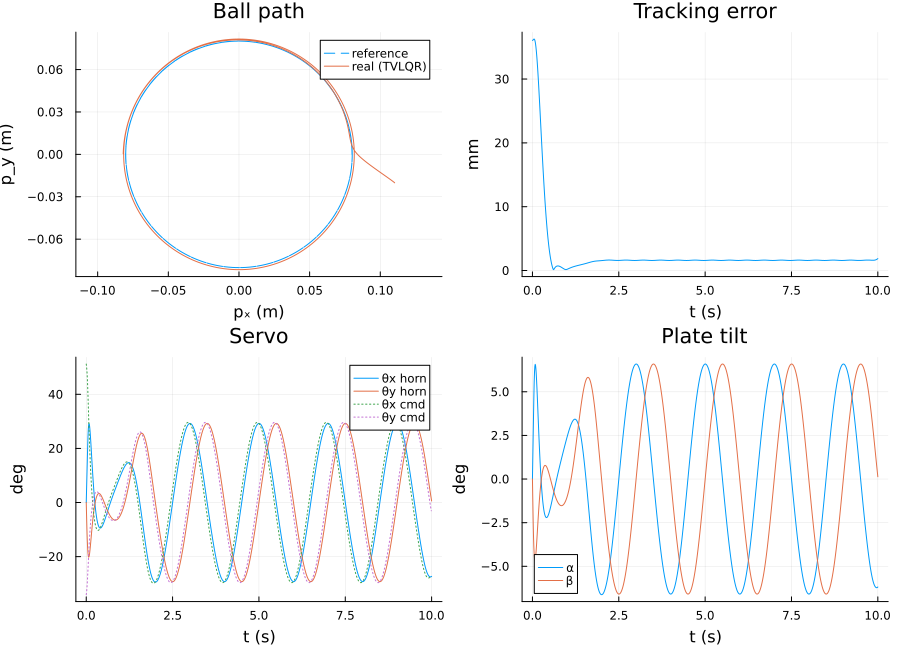

In [5]:
Xm, Xbarm, Um = hcat(X...), hcat(Xbar...), hcat(U...)
plate = hcat([plate_angles(params_real, x) for x in X]...)

p1 = plot(Xbarm[1,:], Xbarm[2,:], ls = :dash, label = "reference", aspect_ratio = :equal,
          xlabel = "pₓ (m)", ylabel = "p_y (m)", title = "Ball path")
plot!(p1, Xm[1,:], Xm[2,:], label = "real (TVLQR)")
p2 = plot(t_vec, 1000*err, xlabel = "t (s)", ylabel = "mm", title = "Tracking error", label = "")
p3 = plot(t_vec, rad2deg.(Xm[5:6,:]'), label = ["θx horn" "θy horn"], xlabel = "t (s)", ylabel = "deg", title = "Servo")
plot!(p3, t_vec[1:end-1], rad2deg.(Um'), ls = :dot, label = ["θx cmd" "θy cmd"])
p4 = plot(t_vec, rad2deg.(plate'), label = ["α" "β"], xlabel = "t (s)", ylabel = "deg", title = "Plate tilt")
display(plot(p1, p2, p3, p4, layout = (2,2), size = (900, 650)))

In [6]:
# animation uses [px, py, α, β] and draws the servo horns + pushrods
Xanim = [[x[1], x[2], plate_angles(params_real, x)...] for x in X]
θs    = [x[5:6] for x in X]
display(animate_ball_plate(Xanim, dt; Xref = Xbar, θs = θs,
                           d_attach = 0.080, r_horn = 0.020 * params_real.ρ / params_est.ρ))

[ Info: Listening on: 127.0.0.1:8700, thread id: 1
┌ Info: MeshCat server started. You can open the visualizer by visiting the following URL in your browser:
└ http://127.0.0.1:8700


MeshCat.DisplayedVisualizer(MeshCat.CoreVisualizer(MeshCat.SceneTrees.SceneNode(nothing, nothing, Dict{String, Vector{UInt8}}(), UInt8[0x83, 0xa7, 0x6f, 0x70, 0x74, 0x69, 0x6f, 0x6e, 0x73, 0x82  …  0x5f, 0x61, 0x6e, 0x69, 0x6d, 0x61, 0x74, 0x69, 0x6f, 0x6e], Dict{String, MeshCat.SceneTrees.SceneNode}("meshcat" => MeshCat.SceneTrees.SceneNode(nothing, nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}("servo2" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x63, 0x61, 0x74, 0x2f, 0x73, 0x65, 0x72, 0x76, 0x6f, 0x32], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "rod2" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x73, 0x68, 0x63, 0x61, 0x74, 0x2f, 0x72, 0x6f, 0x64, 0x32], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "servo1" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x63, 0x61, 0x74, 0x2f, 0x73, 0x65, 0x72, 0x76, 0x6f, 0x31], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "pivot" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x68, 0x63, 0x61, 0x74, 0x2f, 0x70, 0x69, 0x76, 0x6f, 0x74], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "ball" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x73, 0x68, 0x63, 0x61, 0x74, 0x2f, 0x62, 0x61, 0x6c, 0x6c], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "horn1" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x68, 0x63, 0x61, 0x74, 0x2f, 0x68, 0x6f, 0x72, 0x6e, 0x31], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "pedestal" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x74, 0x2f, 0x70, 0x65, 0x64, 0x65, 0x73, 0x74, 0x61, 0x6c], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "plate" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x68, 0x63, 0x61, 0x74, 0x2f, 0x70, 0x6c, 0x61, 0x74, 0x65], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}("ref" => MeshCat.SceneTrees.SceneNode(nothing, nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}("p43" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x74, 0x65, 0x2f, 0x72, 0x65, 0x66, 0x2f, 0x70, 0x34, 0x33], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "p60" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x74, 0x65, 0x2f, 0x72, 0x65, 0x66, 0x2f, 0x70, 0x36, 0x30], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "p28" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x74, 0x65, 0x2f, 0x72, 0x65, 0x66, 0x2f, 0x70, 0x32, 0x38], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "p4" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x61, 0x74, 0x65, 0x2f, 0x72, 0x65, 0x66, 0x2f, 0x70, 0x34], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, MeshCat.SceneTrees.SceneNode}()), "p56" => MeshCat.SceneTrees.SceneNode(UInt8[0x83, 0xa6, 0x6f, 0x62, 0x6a, 0x65, 0x63, 0x74, 0x84, 0xaa  …  0x74, 0x65, 0x2f, 0x72, 0x65, 0x66, 0x2f, 0x70, 0x35, 0x36], nothing, Dict{String, Vector{UInt8}}(), nothing, Dict{String, Mesh